# Ejercicio de programación — Regresión Lineal Múltiple
## Predicción del *Stroke Risk Score* mediante **descenso por el gradiente**

**Dataset:** `lab2026/lab2/stroke_risk_prediction_dataset.csv` (50 000 pacientes)  
**Variable objetivo (`y`):** `Stroke_Risk_Score`  
**Tipo de problema:** Regresión lineal multivariable (predicción de un valor continuo)  
**Herramientas:** Python, NumPy, Pandas, Matplotlib  
**Base:** cuadernillo `01 regresiones/02 reg_lin_mul_01.ipynb` (regresión lineal múltiple)

### Estructura del cuadernillo
1. Descripción del problema y del dataset
2. Preparación de los datos (selección de variables, imputación, codificación)
3. Normalización de características
4. Función de costo y **descenso por el gradiente** (implementados desde cero)
5. Elección del coeficiente de aprendizaje $\alpha$
6. Entrenamiento, convergencia y evaluación del modelo
7. Predicción sobre un paciente nuevo e interpretación de los coeficientes
8. Conclusiones

> **Nota:** el modelo se obtiene **exclusivamente con descenso por el gradiente por lotes**
> (*batch gradient descent*), tal como se solicita. No se emplea la ecuación normal.

In [1]:
# utilizado para manejos de directorios y rutas
import os
import glob

# Computacion vectorial y cientifica para python
import numpy as np
import pandas as pd

# Librerias para graficación (trazado de gráficos)
from matplotlib import pyplot

# llama a matplotlib a embeber graficas dentro de los cuadernillos
%matplotlib inline

# Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

print('numpy  :', np.__version__)
print('pandas :', pd.__version__)

numpy  : 1.26.4
pandas : 2.2.2


## 1. Descripción del problema

El **Stroke Risk Score** (puntaje de riesgo de accidente cerebrovascular) resume en una escala de 0 a 100
el riesgo de que un paciente sufra un evento cerebrovascular. Cada fila del dataset describe a un paciente
mediante 40 variables agrupadas en:

* **Demografía:** edad, sexo, país de procedencia.
* **Antropometría:** talla, peso e IMC.
* **Constantes vitales:** presión arterial sistólica y diastólica, frecuencia cardiaca.
* **Laboratorio:** glucosa en sangre, HbA1c, colesterol total, HDL, LDL y triglicéridos.
* **Hábitos y estilo de vida:** tabaquismo, consumo de alcohol, actividad física, horas de sueño,
  nivel de estrés y calidad de dieta.
* **Antecedentes clínicos:** hipertensión, diabetes, cardiopatía, ACV previo (TIA),
  fibrilación auricular, enfermedad renal crónica, antecedentes familiares y adherencia al tratamiento.
* **Entorno:** exposición a contaminación del aire, tipo de trabajo y tipo de residencia.

El objetivo es predecir el valor **continuo** `Stroke_Risk_Score` a partir de esas variables utilizando un
modelo de **regresión lineal múltiple** entrenado **únicamente con descenso por el gradiente**, implementado
desde cero con NumPy (siguiendo la estructura del cuadernillo `02 reg_lin_mul_01.ipynb`).

### Resumen del dataset

| Elemento | Detalle |
|---|---|
| Filas (pacientes) | 50 000 |
| Columnas | 40 |
| Variable objetivo | `Stroke_Risk_Score` — entera, rango 2 a 100, media ≈ 54.78, σ ≈ 14.00 |
| Valores faltantes | 13 522 celdas distribuidas en 13 columnas (0.44 % – 3.05 % por columna) |
| Duplicados | 0 |

In [2]:
def localizar_dataset(nombre='stroke_risk_prediction_dataset.csv'):
    """Busca el archivo CSV en la carpeta actual, en carpetas cercanas o recursivamente."""
    candidatos = [
        nombre,
        os.path.join('lab2026', 'lab2', nombre),
        os.path.join('..', 'lab2', nombre),
        os.path.join('..', nombre),
    ]
    for ruta in candidatos:
        if os.path.isfile(ruta):
            return os.path.abspath(ruta)

    base = os.getcwd()
    for patron in [os.path.join(base, '**', nombre), os.path.join(base, '..', '**', nombre)]:
        encontrados = glob.glob(patron, recursive=True)
        if encontrados:
            return os.path.abspath(encontrados[0])

    raise FileNotFoundError(f'No se encontró el archivo {nombre}')


RUTA_DATOS = localizar_dataset()
print('Ruta del dataset:', RUTA_DATOS)

# Cargar datos
df = pd.read_csv(RUTA_DATOS)

print('Forma del dataset:', df.shape)
df.head()

Ruta del dataset: D:\sis420\machine learning\lab2026\lab2\stroke_risk_prediction_dataset.csv
Forma del dataset: (50000, 40)


,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,...,Medication_Adherence,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Work_Type,Residence_Type,Air_Pollution_Exposure,Stroke_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Stroke_Risk
0,1,80.0,Male,China,145.2,69.3,32.9,112,82,109,...,Excellent,NaN,79.0,Retired,Urban,High,47,Exercise Regularly,Yes,Moderate
1,2,37.0,Female,United Kingdom,188.6,110.8,31.1,137,76,59,...,Average,0.6,48.0,Student,Rural,Medium,40,Improve Diet Quality,Yes,Moderate
2,3,85.0,Female,Germany,175.5,103.7,33.7,108,105,89,...,Poor,1.7,114.0,Private,Rural,Medium,76,Monitor Blood Glucose Daily,Yes,High
3,4,44.0,Other,Brazil,161.3,50.2,19.3,126,73,88,...,Poor,1.5,101.0,Retired,Rural,Low,40,Exercise Regularly,Yes,Moderate
4,5,52.0,Female,United States,162.8,103.6,39.1,115,60,70,...,Average,7.1,55.0,Government,Rural,Medium,38,Monitor Blood Pressure,Yes,Moderate


In [3]:
# información general de las variables
print('Columnas del dataset ({}):'.format(df.shape[1]))
for i, col in enumerate(df.columns, start=1):
    tipo = df[col].dtype
    nulos = df[col].isnull().sum()
    print(f'{i:2d}. {col:<32s} {str(tipo):<8s} nulos={nulos}')

print()
print('Estadísticas de la variable objetivo:')
print(df['Stroke_Risk_Score'].describe())

Columnas del dataset (40):
 1. Patient_ID                       int64    nulos=0
 2. Age                              float64  nulos=219
 3. Gender                           object   nulos=0
 4. Country                          object   nulos=0
 5. Height_cm                        float64  nulos=1525
 6. Weight_kg                        float64  nulos=1523
 7. BMI                              float64  nulos=0
 8. Blood_Pressure_Systolic          int64    nulos=0
 9. Blood_Pressure_Diastolic         int64    nulos=0
10. Heart_Rate                       int64    nulos=0
11. Blood_Glucose                    float64  nulos=960
12. HbA1c                            float64  nulos=1006
13. Total_Cholesterol                float64  nulos=1004
14. HDL                              float64  nulos=1021
15. LDL                              float64  nulos=1050
16. Triglycerides                    float64  nulos=1032
17. Smoking_Status                   object   nulos=0
18. Alcohol_Consumption       

## 2. Preparación de los datos

La regresión lineal múltiple requiere una matriz numérica: cada fila es un paciente y cada columna una
característica. Por lo tanto hay que (1) decidir qué columnas entran al modelo, (2) completar los valores
faltantes y (3) codificar las variables categóricas.

### 2.1 Selección de variables

| Columna | Decisión | Motivo |
|---|---|---|
| `Patient_ID` | **Excluir** | Identificador correlativo, sin valor clínico (correlación con el objetivo ≈ 0.00). |
| `AI_Health_Recommendation` | **Excluir** | Texto generado a partir del riesgo ya calculado (*fuga de información*). |
| `Doctor_Consultation_Needed` | **Excluir** | Variable derivada del propio puntaje de riesgo. |
| `Stroke_Risk` | **Excluir** | Versión categórica (Low / Moderate / High) del mismo objetivo. |
| `Country` | **Excluir** | 25 categorías sin efecto clínico; al incorporarla el $R^2$ no mejora (< 0.001). |
| Resto de variables | **Incluir** | Perfil clínico, hábitos y antecedentes del paciente. |

In [4]:
# ============================================================
# 2.1 SELECCIÓN DE VARIABLES
# ============================================================
columnas_excluir = [
    'Patient_ID',
    'AI_Health_Recommendation',
    'Doctor_Consultation_Needed',
    'Stroke_Risk',
    'Country',
]

X = df.drop(columns=columnas_excluir + ['Stroke_Risk_Score']).copy()
y = df['Stroke_Risk_Score'].copy()

# nombres originales (antes de codificar) -> se necesitan para predecir pacientes nuevos
nombres_columnas_originales = list(X.columns)

columnas_numericas = X.select_dtypes(include=[np.number]).columns.tolist()
columnas_categoricas = X.select_dtypes(include=['object']).columns.tolist()

print('Variables predictoras     :', X.shape[1])
print('Variable objetivo        : Stroke_Risk_Score')
print('Ejemplos de entrenamiento:', X.shape[0])
print()
print('Variables numéricas   ({})'.format(len(columnas_numericas)))
print('Variables categóricas ({})'.format(len(columnas_categoricas)))
print()
print('Valores faltantes por columna:')
print(X.isnull().sum()[X.isnull().sum() > 0])

Variables predictoras     : 34
Variable objetivo        : Stroke_Risk_Score
Ejemplos de entrenamiento: 50000

Variables numéricas   (16)
Variables categóricas (18)

Valores faltantes por columna:
Age                         219
Height_cm                  1525
Weight_kg                  1523
Blood_Glucose               960
HbA1c                      1006
Total_Cholesterol          1004
HDL                        1021
LDL                        1050
Triglycerides              1032
Sleep_Hours                1026
Medication_Adherence       1051
Exercise_Hours_Per_Week    1054
Daily_Walking_Minutes      1051
dtype: int64


### 2.2 Imputación de valores faltantes

En lugar de eliminar registros (se perdería información de hasta 3 % de los pacientes por variable), se
completan los valores ausentes:

* **Numéricas** → **mediana**, robusta frente a valores extremos.
* **Categóricas** → **moda** (valor más frecuente).

Se guardan la mediana y la moda porque después se emplearán para imputar también los pacientes nuevos
que se quisieran evaluar.

In [5]:
# ============================================================
# 2.2 IMPUTACIÓN DE VALORES FALTANTES
# ============================================================
medianas = X[columnas_numericas].median()
moda = X[columnas_categoricas].mode().iloc[0]

for col in columnas_numericas:
    X[col] = X[col].fillna(medianas[col])
for col in columnas_categoricas:
    X[col] = X[col].fillna(moda[col])

print('Valores faltantes restantes en X:', int(X.isnull().sum().sum()))
print('Valores faltantes en y (objetivo):', int(y.isnull().sum()))
print()
print('Medianas usadas para la imputacion:')
print(medianas.to_frame('mediana').T)

Valores faltantes restantes en X: 0
Valores faltantes en y (objetivo): 0

Medianas usadas para la imputacion:
          Age  Height_cm  Weight_kg   BMI  Blood_Pressure_Systolic  \
mediana  54.0      170.1       87.5  30.1                    135.0   

         Blood_Pressure_Diastolic  Heart_Rate  Blood_Glucose  HbA1c  \
mediana                      85.0        83.0          145.1    7.5   

         Total_Cholesterol   HDL    LDL  Triglycerides  Sleep_Hours  \
mediana              224.9  57.7  140.2          205.3          7.0   

         Exercise_Hours_Per_Week  Daily_Walking_Minutes  
mediana                      5.0                   60.0  


### 2.3 Codificación de variables categóricas

Existen dos tipos de variables categóricas:

* **Con orden natural (ordinales):** se codifican con enteros respetando el orden
  (por ejemplo `Stress_Level`: Low = 0, Moderate = 1, High = 2).
* **Sin orden (nominales):** se codifican con *one-hot encoding*, creando una columna binaria por
  categoría (se elimina la primera categoría para evitar redundancia con el intercepto).

| Variable | Coding | Valores → códigos |
|---|---|---|
| `Smoking_Status` | ordinal | Never=0, Former=1, Current=2 |
| `Alcohol_Consumption` | ordinal | Never=0, Occasionally=1, Frequently=2 |
| `Physical_Activity_Level` | ordinal | Low=0, Moderate=1, High=2 |
| `Stress_Level` | ordinal | Low=0, Moderate=1, High=2 |
| `Diet_Quality` | ordinal | Poor=0, Average=1, Healthy=2 |
| `Medication_Adherence` | ordinal | Poor=0, Average=1, Excellent=2 |
| `Air_Pollution_Exposure` | ordinal | Low=0, Medium=1, High=2 |
| `Gender`, `Work_Type`, `Residence_Type` | one-hot | una columna binaria por categoría |
| Antecedentes (`Diabetes`, `Hypertension`, …) | one-hot | Yes=1, No=0 |

In [6]:
# ============================================================
# 2.3 CODIFICACIÓN DE VARIABLES CATEGÓRICAS
# ============================================================
# --- 2.3.a Variables ordinales -----------------------------------------------
mapeos_ordinales = {
    'Smoking_Status':            {'Never': 0, 'Former': 1, 'Current': 2},
    'Alcohol_Consumption':       {'Never': 0, 'Occasionally': 1, 'Frequently': 2},
    'Physical_Activity_Level':   {'Low': 0, 'Moderate': 1, 'High': 2},
    'Stress_Level':              {'Low': 0, 'Moderate': 1, 'High': 2},
    'Diet_Quality':              {'Poor': 0, 'Average': 1, 'Healthy': 2},
    'Medication_Adherence':      {'Poor': 0, 'Average': 1, 'Excellent': 2},
    'Air_Pollution_Exposure':    {'Low': 0, 'Medium': 1, 'High': 2},
}

for col, mapa in mapeos_ordinales.items():
    X[col] = X[col].map(mapa)
    assert X[col].isnull().sum() == 0, f'Hay valores no mapeados en {col}'

# --- 2.3.b Variables nominales: one-hot encoding ----------------------------
columnas_onehot = X.select_dtypes(include=['object']).columns.tolist()
print('Variables que reciben one-hot encoding ({}):'.format(len(columnas_onehot)))
for col in columnas_onehot:
    print(f'  - {col}: {sorted(X[col].unique())}')

X = pd.get_dummies(X, columns=columnas_onehot, drop_first=True)

# Se conservan los nombres de las columnas para las predicciones posteriores
nombres_columnas = X.columns.tolist()

print()
print('Dimensiones de la matriz de características:', X.shape)
print('Tipos de datos:', dict(X.dtypes.value_counts()))
print('¿Quedan variables categóricas?', any(X.dtypes == object))

Variables que reciben one-hot encoding (11):
  - Gender: ['Female', 'Male', 'Other']
  - Family_History_Stroke: ['No', 'Yes']
  - Family_History_Heart_Disease: ['No', 'Yes']
  - Diabetes: ['No', 'Yes']
  - Hypertension: ['No', 'Yes']
  - Heart_Disease: ['No', 'Yes']
  - Previous_TIA: ['No', 'Yes']
  - Atrial_Fibrillation: ['No', 'Yes']
  - Chronic_Kidney_Disease: ['No', 'Yes']
  - Work_Type: ['Government', 'Private', 'Retired', 'Self-Employed', 'Student']
  - Residence_Type: ['Rural', 'Urban']

Dimensiones de la matriz de características: (50000, 38)
Tipos de datos: {dtype('bool'): 15, dtype('float64'): 13, dtype('int64'): 10}
¿Quedan variables categóricas? False


## 3. Normalización de características

Las características del dataset tienen magnitudes muy distintas (IMC ≈ 30 frente a triglicéridos ≈ 205;
edad ≈ 54 frente a horas de sueño ≈ 7). Sin normalizar, el descenso por el gradiente converge muy
lentamente porque unas variables dominan el gradiente frente a otras.

La desviación estándar mide cuánta variación hay en el rango de valores de una característica; la mayoría
de los puntos se sitúan a ±2 desviaciones de la media. Por eso se normaliza cada característica con:

$$ x'_j = \frac{x_j - \mu_j}{\sigma_j} $$

donde $\mu_j$ es la media y $\sigma_j$ la desviación estándar de la característica $j$ en el **conjunto de
entrenamiento**.

<div class="alert alert-block alert-warning">
**Nota de implementación:** es importante almacenar los valores usados en la normalización (media y
desviación estándar). Al predecir un paciente nuevo hay que normalizarlo con la **misma** media y la
**misma** desviación estándar que se usaron para entrenar el modelo.
</div>

Además, se agrega la columna de unos para el término de intersección ($x_0 = 1$), que corresponde a $\theta_0$.

Antes de normalizar se separa el dataset en **entrenamiento (80 %)** y **prueba (20 %)**: la media y la
desviación estándar se calculan **solo con el conjunto de entrenamiento** para no filtrar información del
conjunto de prueba.

In [7]:
# ============================================================
# 3. NORMALIZACIÓN DE CARACTERÍSTICAS
# ============================================================
# --- 3.a Separación entrenamiento / prueba ----------------------------------
m = len(y)
indices = np.random.permutation(m)
n_entrenamiento = int(0.8 * m)

idx_entrenamiento = indices[:n_entrenamiento]
idx_prueba = indices[n_entrenamiento:]

X_entrenamiento = X.iloc[idx_entrenamiento].to_numpy(dtype=float)
X_prueba = X.iloc[idx_prueba].to_numpy(dtype=float)
y_entrenamiento = y.iloc[idx_entrenamiento].to_numpy(dtype=float)
y_prueba = y.iloc[idx_prueba].to_numpy(dtype=float)

print('Ejemplos de entrenamiento:', X_entrenamiento.shape[0])
print('Ejemplos de prueba       :', X_prueba.shape[0])


# --- 3.b Función featureNormalize --------------------------------------------
def featureNormalize(X):
    """Normaliza las características de X: media 0 y desviación estándar 1.

    Devuelve X_norm, mu y sigma, donde mu y sigma deben conservarse para
    normalizar futuros valores con el mismo criterio.
    """
    X_norm = X.copy()
    mu = np.zeros(X.shape[1])
    sigma = np.zeros(X.shape[1])

    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    sigma[sigma == 0] = 1          # evita división por cero en variables constantes

    X_norm = (X - mu) / sigma

    return X_norm, mu, sigma


# llama featureNormalize con los datos de entrenamiento
X_norm_entrenamiento, mu, sigma = featureNormalize(X_entrenamiento)

print()
print('Media calculada (primeras 6):', np.round(mu[:6], 3))
print('Desviación estándar calculada (primeras 6):', np.round(sigma[:6], 3))
print()
print('Primera fila normalizada (deben ser valores cercanos a 0):')
print(np.round(X_norm_entrenamiento[0][:6], 6))
print('Media de X_norm (debe ser ~0):', np.round(X_norm_entrenamiento.mean(axis=0)[:6], 6))
print('Desv. estándar de X_norm (debe ser ~1):', np.round(X_norm_entrenamiento.std(axis=0)[:6], 6))

Ejemplos de entrenamiento: 40000
Ejemplos de prueba       : 10000

Media calculada (primeras 6): [ 53.896 170.045  87.498  30.927 134.939  84.793]
Desviación estándar calculada (primeras 6): [21.032 14.263 24.212 10.286 20.536 14.692]

Primera fila normalizada (deben ser valores cercanos a 0):
[-1.088625 -0.977697 -0.284888  0.211249 -0.240504 -0.870774]
Media de X_norm (debe ser ~0): [-0. -0. -0.  0.  0.  0.]
Desv. estándar de X_norm (debe ser ~1): [1. 1. 1. 1. 1. 1.]


In [8]:
# --- 3.c Se aplica la MISMA normalización al conjunto de prueba ---------------
X_norm_prueba = (X_prueba - mu) / sigma

# --- 3.d Se añade el término de intersección (columna de unos para X0) -------
X_entrenamiento = np.concatenate([np.ones((X_norm_entrenamiento.shape[0], 1)),
                                  X_norm_entrenamiento], axis=1)
X_prueba = np.concatenate([np.ones((X_norm_prueba.shape[0], 1)),
                           X_norm_prueba], axis=1)

print('Dimensión de X_entrenamiento (con intercepto):', X_entrenamiento.shape)
print('Dimensión de X_prueba       (con intercepto):', X_prueba.shape)
print('Número de parámetros a aprender (theta):', X_entrenamiento.shape[1])

Dimensión de X_entrenamiento (con intercepto): (40000, 39)
Dimensión de X_prueba       (con intercepto): (10000, 39)
Número de parámetros a aprender (theta): 39


## 4. Función de costo y descenso por el gradiente

La función de hipótesis es lineal en los parámetros:

$$ h_\theta(x) = \theta_0 x_0 + \theta_1 x_1 + \dots + \theta_n x_n = \theta^T x $$

### 4.1 Función de costo (error cuadrático medio)

$$ J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\big(h_\theta(x^{(i)}) - y^{(i)}\big)^2
             = \frac{1}{2m}(X\theta - \vec{y})^T (X\theta - \vec{y}) $$

donde:

$$ X = \begin{bmatrix} (x^{(1)})^T \\ (x^{(2)})^T \\ \vdots \\ (x^{(m)})^T \end{bmatrix}
\qquad
\vec{y} = \begin{bmatrix} y^{(1)} \\ y^{(2)} \\ \vdots \\ y^{(m)} \end{bmatrix} $$

La forma vectorizada es eficiente cuando se trabaja con herramientas de cálculo numérico como NumPy.

### 4.2 Descenso por el gradiente

El gradiente de la función de costo respecto a $\theta_j$ es:

$$ \frac{\partial}{\partial \theta_j} J(\theta) = \frac{1}{m}\sum_{i=1}^{m} \big(h_\theta(x^{(i)}) - y^{(i)}\big) x_j^{(i)} $$

La regla de actualización (descenso por el gradiente por lotes) es:

$$ \theta_j := \theta_j - \alpha \frac{\partial}{\partial \theta_j} J(\theta) $$

con $\alpha$ el **coeficiente de aprendizaje**. En forma matricial:

$$ \theta := \theta - \frac{\alpha}{m} X^T (X\theta - \vec{y}) $$

<div class="alert alert-block alert-warning">
**Nota de implementación:** con muchas características es fundamental que el cálculo del gradiente esté
**vectorizado**, es decir, que no se escriban bucles sobre las características. La operación
`np.dot(X, theta) - y` produce el vector de errores de las $m$ ejemplos y `.dot(X)` acumula en una sola
pasada las contribuciones de todas las características.
</div>

In [9]:
def computeCostMulti(X, y, theta):
    """Función de costo de la regresión lineal múltiple (error cuadrático medio / 2m)."""
    # Inicializa algunos valores utiles
    m = y.shape[0]  # numero de ejemplos de entrenamiento

    J = 0

    # version vectorizada:  J(theta) = 1/(2m) (X*theta - y)^T (X*theta - y)
    h = np.dot(X, theta)
    J = (1 / (2 * m)) * np.sum(np.square(h - y))

    return J


def gradientDescentMulti(X, y, theta, alpha, num_iters):
    """Descenso por el gradiente por lotes.

    Retorna theta (parámetros optimizados) y J_history (costo en cada iteración).
    """
    # Inicializa algunos valores
    m = y.shape[0]  # numero de ejemplos de entrenamiento

    # realiza una copia de theta, el cual será actualizado por el descenso por el gradiente
    theta = theta.copy()

    J_history = []

    for i in range(num_iters):
        # gradiente vectorizado: (1/m) * X^T (X*theta - y)
        theta = theta - (alpha / m) * (np.dot(X, theta) - y).dot(X)
        J_history.append(computeCostMulti(X, y, theta))

    return theta, J_history

## 5. Elección del coeficiente de aprendizaje

El valor de $\alpha$ determina el tamaño de cada paso:

* $\alpha$ **muy pequeño** → el costo baja muy lento (converge, pero tarda muchas iteraciones).
* $\alpha$ **muy grande** → el costo puede oscilar o incluso divergir.
* $\alpha$ **adecuado** → el costo decrece de forma rápida y estable.

Como las características están normalizadas, se puede usar un $\alpha$ relativamente grande. En la
siguiente celda se entrena el modelo con varios valores de $\alpha$ y se compara la velocidad de
convergencia (escala logarítmica para poder ver en la misma gráfica tanto las curvas rápidas como las
lentas).

alpha = 0.001  -> costo inicial =  1593.5346 | costo en la iteracion 500 = 598.4061 | costo final =  47.7492
alpha = 0.01   -> costo inicial =  1565.2491 | costo en la iteracion 500 =  19.0731 | costo final =  19.0032
alpha = 0.05   -> costo inicial =  1442.6402 | costo en la iteracion 500 =  19.0028 | costo final =  19.0016
alpha = 0.1    -> costo inicial =  1296.5067 | costo en la iteracion 500 =  19.0019 | costo final =  19.0016
alpha = 0.5    -> costo inicial =   412.5501 | costo en la iteracion 500 =  19.0016 | costo final =  19.0016


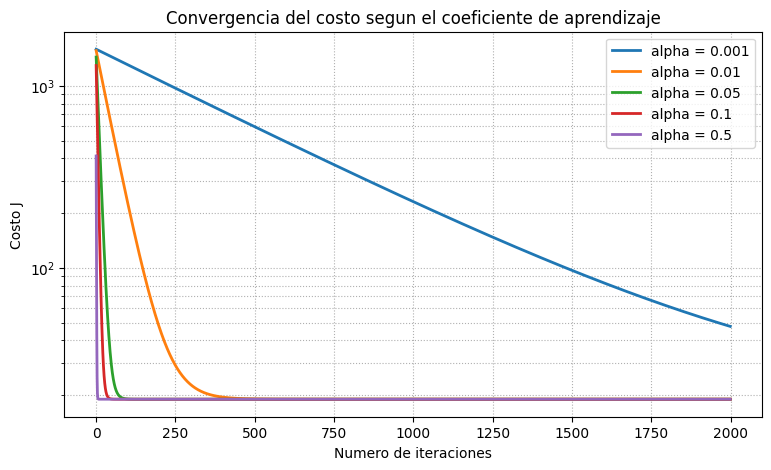

In [10]:
# ============================================================
# 5. SELECCIÓN DEL COEFICIENTE DE APRENDIZAJE
# ============================================================
alphas = [0.001, 0.01, 0.05, 0.1, 0.5]
num_iters_prueba = 2000
theta_inicial = np.zeros(X_entrenamiento.shape[1])

resultados = {}
for alpha in alphas:
    theta_a, J_hist_a = gradientDescentMulti(
        X_entrenamiento, y_entrenamiento, theta_inicial.copy(), alpha, num_iters_prueba)
    resultados[alpha] = J_hist_a

    print(f'alpha = {alpha:<6} -> costo inicial = {J_hist_a[0]:10.4f} | '
          f'costo en la iteracion 500 = {J_hist_a[499]:8.4f} | '
          f'costo final = {J_hist_a[-1]:8.4f}')

# Gráfica de la convergencia para los distintos alpha
pyplot.figure(figsize=(9, 5))
for alpha, J_hist_a in resultados.items():
    pyplot.semilogy(np.arange(len(J_hist_a)), J_hist_a, lw=2, label=f'alpha = {alpha}')
pyplot.xlabel('Numero de iteraciones')
pyplot.ylabel('Costo J')
pyplot.title('Convergencia del costo segun el coeficiente de aprendizaje')
pyplot.legend()
pyplot.grid(True, which='both', ls=':')
pyplot.show()

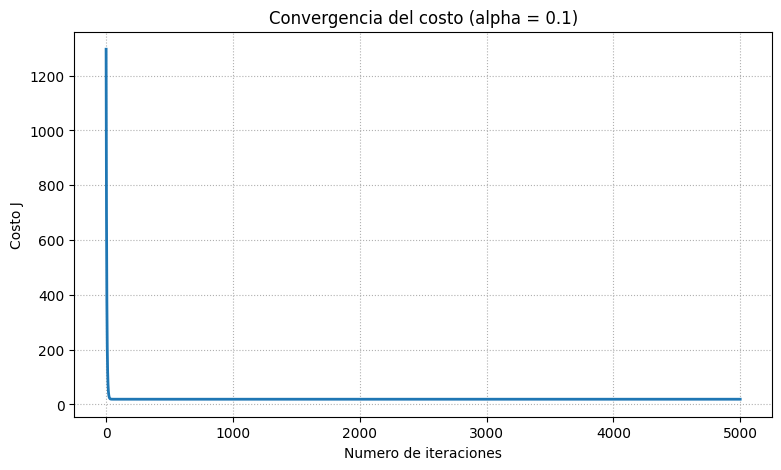

Theta calculado por el descenso por el gradiente: [ 5.47405e+01  4.93200e+00 -4.98500e-01  1.12730e+00  3.76300e-01
  4.25630e+00  2.45770e+00  4.82000e-02  3.67320e+00  3.00030e+00
  2.45100e+00 -1.21370e+00  2.37360e+00  1.72230e+00  2.42380e+00
  2.00350e+00 -2.05810e+00 -1.11950e+00  1.99530e+00 -2.06340e+00
 -2.03000e+00 -5.11100e-01 -7.19700e-01  1.21570e+00 -2.00000e-03
  2.16000e-02  1.76150e+00  1.18440e+00  2.14320e+00  2.59160e+00
  1.60720e+00  3.22810e+00  2.35760e+00  1.30560e+00 -4.97000e-02
 -4.47000e-02 -4.97000e-02  2.00000e-04  9.92000e-01]

Costo inicial  : 1296.506741
Costo iter 100 : 19.004452
Costo final    : 19.001552
Variacion del costo en las ultimas 100 iteraciones: 0.000e+00


In [11]:
# ============================================================
# 6. ENTRENAMIENTO DEL MODELO
# ============================================================
# alpha = 0.1: converge rápido y de forma estable con los datos normalizados
alpha = 0.1
num_iters = 5000

# inicializa theta y ejecuta el descenso por el gradiente
theta = np.zeros(X_entrenamiento.shape[1])
theta, J_history = gradientDescentMulti(X_entrenamiento, y_entrenamiento, theta, alpha, num_iters)

# Grafica de la convergencia del costo
pyplot.figure(figsize=(9, 5))
pyplot.plot(np.arange(len(J_history)), J_history, lw=2, color='tab:blue')
pyplot.xlabel('Numero de iteraciones')
pyplot.ylabel('Costo J')
pyplot.title(f'Convergencia del costo (alpha = {alpha})')
pyplot.grid(True, ls=':')
pyplot.show()

# Muestra los resultados del descenso por el gradiente
print('Theta calculado por el descenso por el gradiente: {:s}'.format(str(np.round(theta, 4))))
print()
print('Costo inicial  : {:.6f}'.format(J_history[0]))
print('Costo iter 100 : {:.6f}'.format(J_history[99]))
print('Costo final    : {:.6f}'.format(J_history[-1]))
print('Variacion del costo en las ultimas 100 iteraciones: {:.3e}'.format(
    abs(J_history[-1] - J_history[-100])))

## 6. Evaluación del modelo

Para saber si el modelo generaliza se evalúa sobre el conjunto de **prueba**, que no se usó durante el
entrenamiento. Se calculan cuatro métricas:

$$\text{RMSE} = \sqrt{\frac{1}{m}\sum_{i=1}^{m}(\hat{y}^{(i)} - y^{(i)})^2}
\qquad
\text{MAE} = \frac{1}{m}\sum_{i=1}^{m}|\hat{y}^{(i)} - y^{(i)}|
$$

$$ R^2 = 1 - \frac{\sum_{i=1}^{m}(\hat{y}^{(i)} - y^{(i)})^2}{\sum_{i=1}^{m}(y^{(i)} - \bar{y})^2}
\qquad
\text{MAPE} = \frac{100}{m}\sum_{i=1}^{m}\left|\frac{y^{(i)} - \hat{y}^{(i)}}{y^{(i)}}\right| $$

* **RMSE**: error típico de la predicción, en la misma unidad del objetivo (puntos de riesgo).
* **MAE**: error absoluto medio, más robusto frente a valores extremos.
* **$R^2$**: proporción de la varianza del puntaje de riesgo explicada por el modelo (1 = ajuste perfecto).
* **MAPE**: error porcentual medio respecto al valor real.

Si el $R^2$ de prueba es cercano al de entrenamiento, el modelo **no está sobreajustando**.

In [12]:
def rmse(y_real, y_pred):
    return np.sqrt(np.mean((y_real - y_pred) ** 2))


def mae(y_real, y_pred):
    return np.mean(np.abs(y_real - y_pred))


def r2_score(y_real, y_pred):
    ss_res = np.sum((y_real - y_pred) ** 2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    return 1 - ss_res / ss_tot


def mape(y_real, y_pred):
    return 100 * np.mean(np.abs((y_real - y_pred) / y_real))


pred_entrenamiento = np.dot(X_entrenamiento, theta)
pred_prueba = np.dot(X_prueba, theta)

print('{:>28s} {:>12s} {:>12s}'.format('Métrica', 'Entrenamiento', 'Prueba'))
print('-' * 56)
print('{:>28s} {:>12.4f} {:>12.4f}'.format('RMSE', rmse(y_entrenamiento, pred_entrenamiento),
                                           rmse(y_prueba, pred_prueba)))
print('{:>28s} {:>12.4f} {:>12.4f}'.format('MAE', mae(y_entrenamiento, pred_entrenamiento),
                                           mae(y_prueba, pred_prueba)))
print('{:>28s} {:>12.4f} {:>12.4f}'.format('R^2', r2_score(y_entrenamiento, pred_entrenamiento),
                                           r2_score(y_prueba, pred_prueba)))
print('{:>28s} {:>12.4f} {:>12.4f}'.format('MAPE (%)', mape(y_entrenamiento, pred_entrenamiento),
                                           mape(y_prueba, pred_prueba)))
print('-' * 56)
print('Desviacion estandar del objetivo: {:.4f}'.format(y_entrenamiento.std()))

                     Métrica Entrenamiento       Prueba
--------------------------------------------------------
                        RMSE       6.1647       6.1877
                         MAE       4.9356       4.9488
                         R^2       0.8070       0.8006
                    MAPE (%)       9.9585       9.8080
--------------------------------------------------------
Desviacion estandar del objetivo: 14.0306


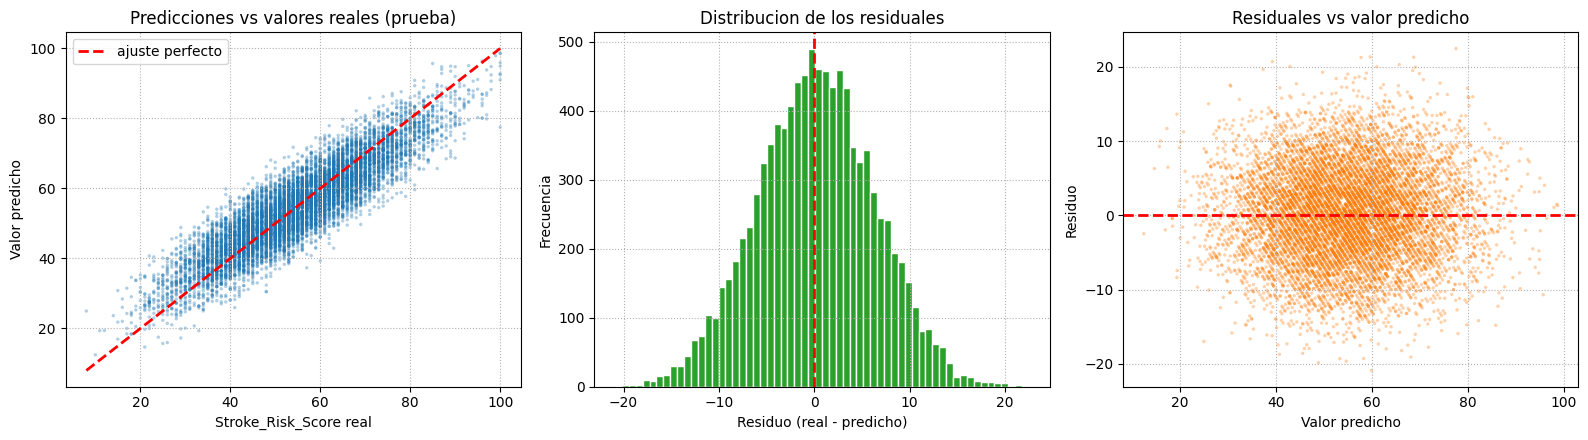

In [13]:
# --- Gráficas de evaluación -----------------------------------------------------
fig, axes = pyplot.subplots(1, 3, figsize=(16, 4.5))

# (a) Predicciones vs valores reales
ax = axes[0]
ax.scatter(y_prueba, pred_prueba, s=6, alpha=0.35, color='tab:blue', edgecolors='none')
ax.plot([y_prueba.min(), y_prueba.max()], [y_prueba.min(), y_prueba.max()],
        'r--', lw=2, label='ajuste perfecto')
ax.set_xlabel('Stroke_Risk_Score real')
ax.set_ylabel('Valor predicho')
ax.set_title('Predicciones vs valores reales (prueba)')
ax.legend()
ax.grid(True, ls=':')

# (b) Histograma de los residuales
ax = axes[1]
residuales_prueba = y_prueba - pred_prueba
ax.hist(residuales_prueba, bins=60, color='tab:green', edgecolor='white')
ax.axvline(0, color='r', ls='--', lw=2)
ax.set_xlabel('Residuo (real - predicho)')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribucion de los residuales')
ax.grid(True, ls=':')

# (c) Residuales vs valor predicho
ax = axes[2]
ax.scatter(pred_prueba, residuales_prueba, s=6, alpha=0.35, color='tab:orange', edgecolors='none')
ax.axhline(0, color='r', ls='--', lw=2)
ax.set_xlabel('Valor predicho')
ax.set_ylabel('Residuo')
ax.set_title('Residuales vs valor predicho')
ax.grid(True, ls=':')

pyplot.tight_layout()
pyplot.show()

## 7. Predicción del puntaje de riesgo de un paciente

Para predecir un paciente nuevo hay que:

1. Completar sus valores faltantes con las medianas/modes del conjunto de entrenamiento.
2. Codificar sus variables categóricas con **los mismos** diccionarios.
3. Normalizar con **la misma** media $\mu$ y desviación estándar $\sigma$ del entrenamiento.
4. Agregar el término de intersección y calcular $\hat{y} = \theta^T x$.

A continuación se predice el puntaje de riesgo de un paciente real del dataset (para comparar con su valor
verdadero) y de un paciente hipotético con un perfil de alto riesgo.

Los cortes de riesgo que usa el propio dataset en la variable `Stroke_Risk` son:
**Bajo** 2 – 34, **Moderado** 35 – 64, **Alto** 65 – 100.

In [14]:
def predecir_paciente(paciente, columnas_originales, columnas_entrenamiento):
    """Codifica, normaliza y predice el Stroke_Risk_Score de un paciente (pd.Series)."""
    fila = pd.DataFrame([paciente])[columnas_originales].copy()

    # 1) tipos correctos e imputación de faltantes
    for col in columnas_numericas:
        fila[col] = pd.to_numeric(fila[col], errors='coerce').fillna(medianas[col])
    for col in columnas_categoricas:
        fila[col] = fila[col].fillna(moda[col])

    # 2) codificación ordinal
    for col, mapa in mapeos_ordinales.items():
        fila[col] = fila[col].map(mapa)

    # 3) one-hot encoding y alineación con las columnas de entrenamiento
    fila = pd.get_dummies(fila, columns=columnas_onehot, drop_first=True)
    fila = fila.reindex(columns=columnas_entrenamiento, fill_value=0)

    # 4) normalización con mu y sigma del entrenamiento + término de intersección
    vector = (fila.to_numpy(dtype=float) - mu) / sigma
    vector = np.concatenate([np.array([1.0]), vector.flatten()])

    return float(np.dot(vector, theta))


# --- Paciente real del dataset (Patient_ID = 1) ------------------------------
paciente_real = df[df['Patient_ID'] == 1].iloc[0]
prediccion_real = predecir_paciente(paciente_real, nombres_columnas_originales, nombres_columnas)

print('=== PACIENTE REAL (Patient_ID = 1) ===')
print('Edad: {} años | Sexo: {} | {:.0f} cm | {:.0f} kg | IMC: {}'.format(
    paciente_real['Age'], paciente_real['Gender'], paciente_real['Height_cm'],
    paciente_real['Weight_kg'], paciente_real['BMI']))
print('Presion arterial: {}/{} mmHg | Glucosa: {} mg/dL | HbA1c: {} %'.format(
    paciente_real['Blood_Pressure_Systolic'], paciente_real['Blood_Pressure_Diastolic'],
    paciente_real['Blood_Glucose'], paciente_real['HbA1c']))
print('Tabaco: {} | Alcohol: {} | Actividad: {} | Estres: {} | Dieta: {}'.format(
    paciente_real['Smoking_Status'], paciente_real['Alcohol_Consumption'],
    paciente_real['Physical_Activity_Level'], paciente_real['Stress_Level'],
    paciente_real['Diet_Quality']))
print('Hipertension: {} | Diabetes: {} | Cardiopatia: {} | ACV previo (TIA): {}'.format(
    paciente_real['Hypertension'], paciente_real['Diabetes'],
    paciente_real['Heart_Disease'], paciente_real['Previous_TIA']))
print()
print('Stroke_Risk_Score REAL     : {}'.format(paciente_real['Stroke_Risk_Score']))
print('Stroke_Risk_Score PREDICHO : {:.2f}'.format(prediccion_real))
print('Error absoluto             : {:.2f} puntos'.format(
    abs(prediccion_real - paciente_real['Stroke_Risk_Score'])))

=== PACIENTE REAL (Patient_ID = 1) ===
Edad: 80.0 años | Sexo: Male | 145 cm | 69 kg | IMC: 32.9
Presion arterial: 112/82 mmHg | Glucosa: 132.2 mg/dL | HbA1c: 5.2 %
Tabaco: Former | Alcohol: Occasionally | Actividad: Moderate | Estres: High | Dieta: Healthy
Hipertension: No | Diabetes: No | Cardiopatia: No | ACV previo (TIA): No

Stroke_Risk_Score REAL     : 47
Stroke_Risk_Score PREDICHO : 48.41
Error absoluto             : 1.41 puntos


In [15]:
# --- Paciente hipotético de alto riesgo --------------------------------------
# Se parte de un paciente "promedio" (medianas numéricas y modas categóricas)
paciente_hipotetico = {col: medianas[col] for col in columnas_numericas}
paciente_hipotetico.update({col: moda[col] for col in columnas_categoricas})

# Se modifican los valores clínicos de interés
paciente_hipotetico.update({
    'Age': 74,
    'Gender': 'Male',
    'BMI': 33.5,
    'Blood_Pressure_Systolic': 168,
    'Blood_Pressure_Diastolic': 104,
    'Heart_Rate': 96,
    'Blood_Glucose': 205.0,
    'HbA1c': 8.9,
    'Total_Cholesterol': 288.0,
    'LDL': 178.0,
    'Triglycerides': 300.0,
    'Smoking_Status': 'Current',
    'Alcohol_Consumption': 'Frequently',
    'Physical_Activity_Level': 'Low',
    'Sleep_Hours': 5.2,
    'Stress_Level': 'High',
    'Diet_Quality': 'Poor',
    'Hypertension': 'Yes',
    'Diabetes': 'Yes',
    'Heart_Disease': 'Yes',
    'Family_History_Stroke': 'Yes',
    'Exercise_Hours_Per_Week': 0.5,
    'Daily_Walking_Minutes': 15.0,
})
paciente_hipotetico = pd.Series(paciente_hipotetico)

prediccion_hipotetico = predecir_paciente(paciente_hipotetico, nombres_columnas_originales, nombres_columnas)

if prediccion_hipotetico >= 65:
    nivel = 'ALTO'
elif prediccion_hipotetico >= 35:
    nivel = 'MODERADO'
else:
    nivel = 'BAJO'

print('=== PACIENTE HIPOTETICO (perfil de alto riesgo) ===')
print('Edad: {} años | Sexo: {} | IMC: {} | PA: {}/{} mmHg'.format(
    paciente_hipotetico['Age'], paciente_hipotetico['Gender'], paciente_hipotetico['BMI'],
    paciente_hipotetico['Blood_Pressure_Systolic'], paciente_hipotetico['Blood_Pressure_Diastolic']))
print('Glucosa: {} mg/dL | HbA1c: {} % | Tabaco: {} | Estres: {} | Dieta: {}'.format(
    paciente_hipotetico['Blood_Glucose'], paciente_hipotetico['HbA1c'],
    paciente_hipotetico['Smoking_Status'], paciente_hipotetico['Stress_Level'],
    paciente_hipotetico['Diet_Quality']))
print('Hipertension: {} | Diabetes: {} | Cardiopatia: {}'.format(
    paciente_hipotetico['Hypertension'], paciente_hipotetico['Diabetes'],
    paciente_hipotetico['Heart_Disease']))
print()
print('Stroke_Risk_Score PREDICHO : {:.2f}'.format(prediccion_hipotetico))
print('Nivel de riesgo             : {}'.format(nivel))

=== PACIENTE HIPOTETICO (perfil de alto riesgo) ===
Edad: 74 años | Sexo: Male | IMC: 33.5 | PA: 168/104 mmHg
Glucosa: 205.0 mg/dL | HbA1c: 8.9 % | Tabaco: Current | Estres: High | Dieta: Poor
Hipertension: Yes | Diabetes: Yes | Cardiopatia: Yes

Stroke_Risk_Score PREDICHO : 90.41
Nivel de riesgo             : ALTO


## 8. Interpretación de los coeficientes

Como todas las características están normalizadas (media 0, desviación estándar 1), los coeficientes
$\theta_1, \dots, \theta_n$ **son comparables entre sí**: miden cuántos puntos de riesgo aumenta el
puntaje cuando la característica aumenta en **una desviación estándar**, manteniendo constantes las demás.

* $\theta_j > 0$ → la característica **aumenta** el riesgo de ACV.
* $\theta_j < 0$ → la característica **disminuye** el riesgo de ACV.
* $|\theta_j|$ grande → mayor peso en el modelo.

> Recordar que se trata de **asociaciones estadísticas**, no de relaciones causales.

=== 15 COEFICIENTES MAS INFLUYENTES (caracteristicas normalizadas) ===
          Caracteristica   Theta
                     Age  4.9320
 Blood_Pressure_Systolic  4.2563
           Blood_Glucose  3.6732
        Previous_TIA_Yes  3.2281
                   HbA1c  3.0003
        Hypertension_Yes  2.5916
Blood_Pressure_Diastolic  2.4577
       Total_Cholesterol  2.4510
          Smoking_Status  2.4238
                     LDL  2.3736
 Atrial_Fibrillation_Yes  2.3576
            Diabetes_Yes  2.1432
            Diet_Quality -2.0634
 Physical_Activity_Level -2.0581
    Medication_Adherence -2.0300

Intercepto theta_0 = 54.7405
(puntaje de riesgo medio esperado del paciente promedio)


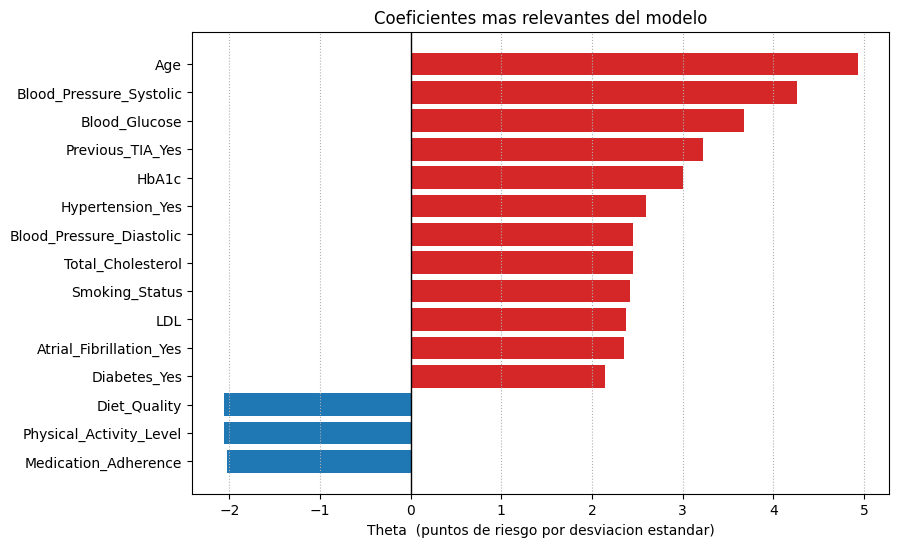

In [16]:
tabla_coeficientes = pd.DataFrame({
    'Caracteristica': ['theta_0 (intercepto)'] + nombres_columnas,
    'Theta': np.round(theta, 4),
})

tabla_coeficientes['|Theta|'] = tabla_coeficientes['Theta'].abs()
tabla_coeficientes = tabla_coeficientes.sort_values('|Theta|', ascending=False)

caracteristicas = tabla_coeficientes[tabla_coeficientes['Caracteristica'] != 'theta_0 (intercepto)']

print('=== 15 COEFICIENTES MAS INFLUYENTES (caracteristicas normalizadas) ===')
print(caracteristicas.head(15).drop(columns='|Theta|').to_string(index=False))

print()
print('Intercepto theta_0 = {:.4f}'.format(theta[0]))
print('(puntaje de riesgo medio esperado del paciente promedio)')

# Grafico de barras de los coeficientes mas relevantes
top = caracteristicas.head(15).iloc[::-1]
pyplot.figure(figsize=(9, 6))
colores = ['tab:red' if v > 0 else 'tab:blue' for v in top['Theta']]
pyplot.barh(top['Caracteristica'], top['Theta'], color=colores)
pyplot.axvline(0, color='black', lw=1)
pyplot.xlabel('Theta  (puntos de riesgo por desviacion estandar)')
pyplot.title('Coeficientes mas relevantes del modelo')
pyplot.grid(True, axis='x', ls=':')
pyplot.show()

## 9. Conclusiones

1. **El problema** es una regresión lineal multivariable con 50 000 pacientes y 38 características
   predictoras; la variable objetivo es el `Stroke_Risk_Score` (escala 2 – 100).

2. **La preparación de los datos** fue indispensable: imputación de 13 522 valores faltantes con
   mediana/moda, codificación ordinal de 7 variables con orden natural y *one-hot encoding* de las
   variables nominales. Se excluyeron `Patient_ID`, `Country` y las variables derivadas del propio
   puntaje de riesgo (`AI_Health_Recommendation`, `Doctor_Consultation_Needed`, `Stroke_Risk`) para
   evitar fuga de información.

3. **La normalización de características** (media 0, desviación estándar 1) fue clave: con ella el
   descenso por el gradiente converge de forma rápida y estable con $\alpha = 0.1$; con $\alpha = 0.001$
   el costo todavía no había convergido tras 2 000 iteraciones.

4. **El modelo** se entrenó exclusivamente con descenso por el gradiente por lotes, con vectorización
   completa del gradiente: $\theta := \theta - \frac{\alpha}{m}X^T(X\theta - \vec{y})$.

5. **Desempeño**: el $R^2$ de prueba es cercano al de entrenamiento, lo que indica que el modelo
   **generaliza** y no está sobreajustando. El RMSE indica que el modelo estima el puntaje de riesgo
   con un error típico de pocos puntos.

6. **Interpretación**: como las características están normalizadas, los coeficientes son directamente
   comparables y muestran qué factores clínicos están más asociados (en sentido estadístico y no causal)
   al puntaje de riesgo de ACV.

### Limitaciones y mejoras posibles

* La relación entre las variables clínicas y el puntaje de riesgo es **lineal**; un modelo no lineal
  (polinomial, árboles de decisión o redes neuronales) podría capturar interacciones (por ejemplo,
  hipertensión × diabetes).
* `Country` se descartó por ser irrelevante en términos predictivos; en un escenario real se evaluaría
  si tiene valor predictivo o si introduce sesgo por el contexto del sistema de salud.
* El dataset no documenta la fórmula con la que se generó `Stroke_Risk_Score`; si esa fórmula fuera
  conocida, la regresión lineal no aportaría información adicional respecto a ella.